# **Projet — Stress hydrique dans les forêts du Valais Central**

<i>Basile Meichtry, d'après le cours de Géoinformatique II, UNIL</i>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<i>10 novembre 2026</i>

Ce notebook a pour objectif de documenter le projet, en présentant la méthode employée et les résultats obtenus.  
<br><br>
### **Question de recherche**

Peut-on prédire le stress hydrique des surfaces forestières du Valais central en 2018 à partir du relief et des caractéristiques de l'urbanisation environnante, sans utiliser de données climatiques ?

### **Contexte**
Le Valais central est particulièrement exposé à la sécheresse en raison de son climat intra-alpin. Le stress hydrique chez les arbres peut limiter leur activité photosynthétique. Le rapport entre évapotranspiration réelle et évapotranspiration potentielle (ET/ETp) permet d'évaluer cette contrainte: une valeur inférieure à 0.8 peut indiquer des conditions de sécheresse affectant la végétation.

Plusieurs facteurs pourraient influencer la répartition spatiale de cet indice. L'urbanisation, notamment par l'imperméabilisation des sols et l'effet d'îlot de chaleur urbain, pourrait modifier la disponibilité en eau pour les forêts. Le relief, à travers l'altitude et la pente, peut également influencer les conditions locales d'exposition et de disponibilité en eau et sera pris en compte dans l'analyse.

Il est donc pertinent d'évaluer dans quelle mesure les caractéristiques topographiques et urbaines permettent de prédire les variations spatiales du stress hydrique forestier, sans intégrer directement de variables climatiques au modèle, afin d'identifier les secteurs potentiellement vulnérables.

### **Hypothèses**

1. Les caractéristiques topographiques expliquent une partie de la variabilité spatiale du stress hydrique.
2. L'ajout de variables liées à l'urbanisation améliore les performances prédictives du modèle fondé uniquement sur le relief.
3. Le relief et l'urbanisation ne suffisent pas à expliquer toute la variabilité observée, en raison de l'absence de variables climatiques.

### *Zone d'étude**
La zone d'étude comprend les districts de Conthey, Sion, Sierre et  Hérens situés dans le canton du Valais, en Suisse.  Le choix de cette zone d'étude permet de considérer une région présentant une diversité de conditions topographiques et environnementales. Cette restriction vise également à réduire les temps de calcul, certaines opérations spatiales sur les couches vectorielles s'avérant particulièrement coûteuses en ressources informatiques.

L'analyse portera sur les surfaces forestières, dont la délimitation repose sur une couche de polygones forestiers datant de 2021. L'indice de stress hydrique étudié correspond quant à lui à l'année 2018. Le décalage temporel entre ces données représente une limite méthodologique. En effet, certaines surfaces forestières ont pu évoluer entre 2018 et 2021. En l'absence d'une couche forestière correspondant à 2018, les données de 2021 seront utilisées comme approximation de la distribution spatiale des forêts durant la période étudiée.

### **Variables**
- **Variable à expliquer** : Indice ET/ETp - rapport entre l'évapotranspiration réelle et l'évapotranspiration potentielle pour l'année 2018. Cette variable représente l'indice de stress hydrique étudié.

- **Variables explicatives** : Les variables explicatives sont réparties en deux groupes.<u><br>Caractéristiques topographiques :</u>
Altitude moyenne du pixel (m) ; Pente moyenne du pixel (°).<u><br>Caractéristiques de l'urbanisation :</u>
Densité urbaine (%) : proportion de la surface du pixel occupée par les zones urbanisées ;
Distance aux zones urbanisées (m) : distance entre le centroïde du pixel forestier et la zone urbanisée la plus proche.<br>

### **Données**
Les données utilisées dans ce projet sont réunies dans l'archive `Meichtry_Basile_projet.zip` téléchargeable via le lien situé tout en haut de la page. Cette archive contient une geodatabase unique `Meichtry_Basile_projet.gpkg` regroupant les couches vectorielles, ainsi que les fichier rasters au format GeoTIFF.

Les couches rasters et vectorielles sont nommées à l'aide de préfixes, selon leur rôle:
- `source_` : données sources ;

- `temp_` : résultats intermédiaires ;

- `input_`: données résultant de la chaîne de prétraitement et utilisées comme entrées de la régression ;

- `results_` : données finales résultant de l'analyse et utilisées pour la réalisation des cartes. <br>

Toutes les données sont exprimées dans le système de coordonnées LV95 (CH1903+ / LV95, EPSG:2056) ; les altitudes, lorsqu'elles existent, sont référencées au système altimétrique LN02 (EPSG:5728).
<br><br>

| Données utilisées | Nom de la couche originale | Nom de la couche dans l'archive ZIP | Fournisseur | Type | Lien de téléchargement | Date de téléchargement | Système de coordonnées | Résolution / échelle | Rôle dans l'analyse |
|---|---|---|---|---|---|---|---|---|---|
|Indice ET/ETp 2018|wald-wasserverfuegbarkeit_pflanzen_2018|`source_Indice_ETETp`|Federal Office for the Environment FOEN|Raster|[data.geo.admin](https://data.geo.admin.ch/ch.bafu.wald-wasserverfuegbarkeit_pflanzen/wald-wasserverfuegbarkeit_pflanzen_2018/wald-wasserverfuegbarkeit_pflanzen_2018_2056.tif)|27.10.2026|EPSG:2056 - CH1903+ / LV95|250x250| variable à expliquer
|Modèle Numérique de Terrain| swissALTIRegio|`source_MNT_10x10m_clip` (version découpée)| swisstopo| Raster|[swisstopo]( https://www.swisstopo.admin.ch/fr/modele-altimetrique-swissaltiregio) |01.11.2026|EPSG:2056 - CH1903+ / LV95| 10x10m| variable d’entrée pour le calcul de l’altitude et de la pente
|Routes 2021| swissTLM3D_2021 (TLM_STRASSE)|`source_Routes_clip` (version découpée) |swisstopo| vecteur (lignes)| [swisstopo](https://www.swisstopo.admin.ch/de/landschaftsmodell-swisstlm3d)| 27.10.2026|LV95 LN02| 0.2-1.5m| variable d’entrée pour calcul de distance et de densité|
|Bâtiments 2021| swissTLM3D_2021 (TLM_GEBAEUDE_FOOTPRINT)|`source_Batiments_clip` (version découpée)| swisstopo| vecteur (polygones)|[swisstopo](https://www.swisstopo.admin.ch/de/landschaftsmodell-swisstlm3d) |27.10.2026| LV95 LN02| 0.2-1.5m| variable d’entrée pour calcul de distance et de densité|
|Couverture du sol 2021| swissTLM3D_2021 (TLM_BODENBEDECKUNG)|`source_Couverture_du_sol` |swisstopo|vecteur (polygones)|[swisstopo](https://www.swisstopo.admin.ch/de/landschaftsmodell-swisstlm3d)| 27.10.2026| LV95 LN02| 1-3m|variable d’entrée et délimitation des surfaces forestières|
|Limites des districts |swissBOUNDARIES3D (TLM_BEZIRKSGEBIET)|  `source_limite_districts`|swisstopo| vecteur (polygones)|[swisstopo]( https://www.swisstopo.admin.ch/fr/modele-du-territoire-swissboundaries3d)| 27.10.2026|LV95 LN02| ± 0,5 m|Délimitation de la zone d’étude|

<br><br> Afin de respecter la limite de taille imposée pour l'archive finale (2 Go), certaines données sources ont été découpées à l'étendue de la zone d'étude, sans modification de leur résolution spatiale ou de leur contenu à l'intérieur de cette zone. Cela concernce le MNT, les bâtiments et les routes. Seules ces versions découpées sont fournies dans l'archive du projet.

Le modèle de traitement QGIS (`Stress_hydrique.model3`) est toutefois conservé dans sa version originale, avec les étapes de découpage des données sources. Il n'a donc pas été adapté aux versions préalablement découpées fournies dans l'archive. Ces étapes sont simplement réappliquées lors de l'exécution du modèle. Ainsi, le même modèle peut être utilisé aussi bien avec les données découpées fournies dans l'archive qu'avec les données sources originales complètes, téléchargées séparément auprès des fournisseurs.

La couche préfixée `input_` a été créee à l'aide du modeleur graphique de QGIS. Les couches `temp_` correspondent aux résultats intermédiaires de cette chaîne de traitements. La plupart ont été exclues de l'archive finale, car elles peuvent être régénérées à l'aide du modèle `Stress_hydrique.model3`, également fourni dans l'archive `Meichtry_Basile_projet.zip`.

Ce notebook permet de poursuivre la chaîne de traitements et d'ajouter à la géodatabase les couches préfixées `results_`.


### Reproduire ce notebook

1. **Données** : Téléchargez `Meichtry_Basile_projet.zip` depuis le haut de cette page et décompressez-le pour obtenir le dossier `Meichtry_Basile_projet/`. Les chemins d'accès sont relatifs et définis dans les cellules de configuration (§1). Il est important de conserver l'organisation des dossiers.

2. **Environnement** : Ce notebook a été développé dans **Google Colab**.
Les versions des six bibliothèques utilisées (`numpy, pandas, rasterio, geopandas, matplotlib et scikit-learn`) sont indiquées dans le fichier `requirements.txt`. La version de Python utilisée est également précisée dans le fichier. Pour installer les mêmes versions de bibliothèques, exécutez la commande suivante dans un terminal ouvert dans le dossier du projet: `pip install -r requirements.txt`.<br>
La version de Python doit être compatible avec les versions des bibliothèques indiquées dans le fichier.

3. **Exécution** : Ouvrez le notebook dans Google Colab ou dans un environnement Jupyter local, puis exécutez les cellules dans l'ordre, à l'aide de l'option « Exécuter toutes les cellules » (Run all).
La graine aléatoire est fixée dans la cellule de configuration (§1).

## Plan

1. Configuration · 2. Données sources · 3. Analyse exploratoire · 4. Chaîne de pré-traitements · 5. Modélisation et choix du modèle · 6. Analyse des résidus · 7. Carte des prédictions et incertitude · 8. Export des résultats · 9. Conclusion








---
## **1. Configuration**

In [180]:
#A SUPPRIMER LORS DU RENDU, UTILE POUR COLAB#
import zipfile
import os
zip_path = "/content/Meichtry_Basile_projet.zip"
extract_path = "/content/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Décompression terminée !")
print("Fichiers trouvés dans la session active :")
os.listdir("/content/")

Décompression terminée !
Fichiers trouvés dans la session active :


['.config',
 'Meichtry_Basile_projet.zip',
 '.ipynb_checkpoints',
 'drive',
 'Meichtry_Basile_projet',
 'sample_data']

In [181]:
# Bibliothèques
import sys
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import sklearn
import rasterio.plot

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from rasterio.mask import mask
from rasterio.transform import array_bounds
from shapely.geometry import mapping

# Chemins relatifs au dossier du notebook
PROJET = Path("Meichtry_Basile_projet")

GPKG = PROJET / "Meichtry_Basile_projet.gpkg"
RASTER_ET_ETP = PROJET / "source_Indice_ETETp.tif"
RASTER_MNT = PROJET / "source_MNT_10x10m_clip.tif"

# Vérification de la présence des fichiers
fichiers = [GPKG, RASTER_ET_ETP, RASTER_MNT]

for fichier in fichiers:
    if fichier.exists():
        print(f"Fichier trouvé : {fichier}")
    else:
        raise FileNotFoundError(f"Fichier introuvable : {fichier}")

print("Tous les fichiers nécessaires ont été trouvés.")
# Graine aléatoire
SEED = 21

# Affichage des versions utilisées
print('\n'
    f"Exécution du notebook le {date.today():%d.%m.%Y}\n"
    "Versions :\n"
    f"Python {sys.version.split()[0]}, "
    f"numpy {np.__version__}, "
    f"pandas {pd.__version__}, "
    f"geopandas {gpd.__version__}, "
    f"rasterio {rasterio.__version__}, "
    f"scikit-learn {sklearn.__version__}"
)


Fichier trouvé : Meichtry_Basile_projet/Meichtry_Basile_projet.gpkg
Fichier trouvé : Meichtry_Basile_projet/source_Indice_ETETp.tif
Fichier trouvé : Meichtry_Basile_projet/source_MNT_10x10m_clip.tif
Tous les fichiers nécessaires ont été trouvés.

Exécution du notebook le 13.11.2026
Versions :
Python 3.13.18, numpy 2.4.6, pandas 2.2.3, geopandas 1.2.0, rasterio 1.5.2, scikit-learn 1.6.1


---
## **2. Données sources**
### **2.1 Couches vectorielles**

In [189]:
couches = gpd.list_layers(GPKG)
print(f"Couches présentes dans le .gpkg : \n {couches}")



Couches présentes dans le .gpkg : 
                        name      geometry_type
0   source_limite_districts     MultiPolygon Z
1  source_Couverture_du_sol     MultiPolygon Z
2           temp_zone_etude     MultiPolygon Z
3      input_grille_analyse            Polygon
4     source_Batiments_clip     MultiPolygon Z
5        source_Routes_clip  MultiLineString Z


In [ ]:
source_limite_districts = gpd.read_file(GPKG, layer="source_limite_districts")
source_couverture_du_sol = gpd.read_file(GPKG, layer="source_Couverture_du_sol")
source_routes_clip = gpd.read_file(GPKG, layer="source_Routes_clip")
source_batiments_clip = gpd.read_file(GPKG, layer="source_Batiments_clip")
for nom, gdf in [("Limites_districts",source_limite_districts), ("Couverture_du_sol",source_couverture_du_sol), ("Routes",source_routes_clip), ("Batiments",source_batiments_clip)]:
     print(
        f"{nom:<20} | "
        f"{len(gdf):>10,} entités | "
        f"SCR : {gdf.crs.name:<25} | "
        f"Géométrie : {gdf.geom_type.iloc[0]}"
    )


### 2.2 Couches Raster

Les deux rasters sources présentant des résolutions spatiales différentes, leur combinaison nécessite une étape de traitement spécifique, qui sera détaillée dans la section consacrée aux prétraitements.


In [ ]:
RASTERS = {
    'altitude':        'source_MNT_10x10m_clip.tif',
    'Stress_hydrique':           'source_Indice_ETETp.tif',
}

metadonnees = []
for fichier in list(RASTERS.values()):
    with rasterio.open(PROJET / fichier) as src:
        metadonnees.append({
            'fichier': fichier, 'SCR': f'EPSG:{src.crs.to_epsg()}',
            'lignes × colonnes': f'{src.height} × {src.width}', 'résolution (m)': src.res[0],
            'coin supérieur gauche': f'({src.transform.c:.0f}, {src.transform.f:.0f})',
            'type': src.dtypes[0], 'NoData': src.nodata,
        })
pd.DataFrame(metadonnees).set_index('fichier')



---
## **3. Analyse exploratoire des données brutes**

Cette section introduit visuellement et statistiquement les données sources
utilisées lors du projet.<br><br>


### **3.1 Stress hydrique - Variable à expliquer**

Résolution : (250.0, 250.0)
Valeur minimale : 0
Valeur maximale : 100
Moyenne : 79.193
Médiane : 86.0
Écart-type : 22.344


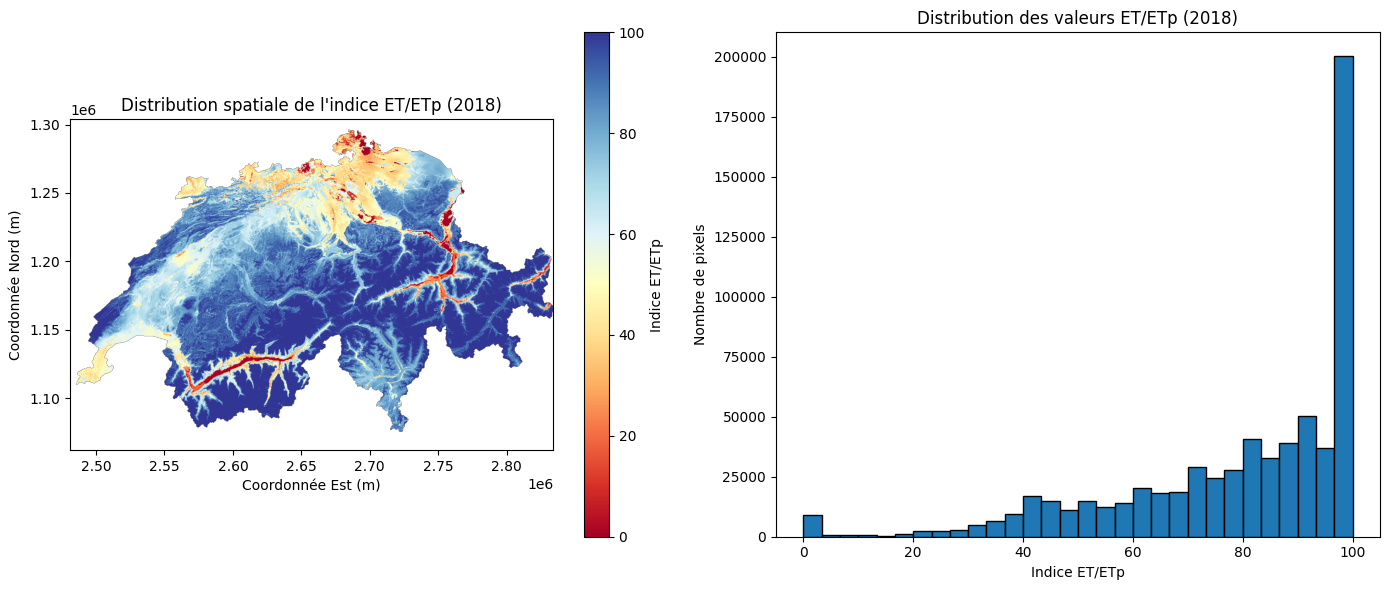

In [185]:
#Exploration de l'indice du stress hydrique

with rasterio.open(RASTER_ET_ETP) as src:
    et_etp = src.read(1, masked=True) # masquer les valeurs NoData
    extent = rasterio.plot.plotting_extent(src)

# Statistiques descriptives
print("Résolution :", src.res)
print(f"Valeur minimale : {et_etp.min()}")
print(f"Valeur maximale : {et_etp.max()}")
print(f"Moyenne : {et_etp.mean():.3f}")
print(f"Médiane : {np.ma.median(et_etp)}")
print(f"Écart-type : {et_etp.std():.3f}")

# Carte et histogramme côte à côte
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Carte du raster
im = ax[0].imshow(
    et_etp,
    cmap="RdYlBu",
    extent=extent,
    origin="upper"
)

fig.colorbar(im, ax=ax[0], label="Indice ET/ETp")
ax[0].set_title("Distribution spatiale de l'indice ET/ETp (2018)")
ax[0].set_xlabel("Coordonnée Est (m)")
ax[0].set_ylabel("Coordonnée Nord (m)")

# Histogramme
ax[1].hist(et_etp.compressed(), bins=30, edgecolor="black")
ax[1].set_title("Distribution des valeurs ET/ETp (2018)")
ax[1].set_xlabel("Indice ET/ETp")
ax[1].set_ylabel("Nombre de pixels")

plt.tight_layout()
plt.show()


### **3.2 Variables explicatives**

### **3.2.1 Visualisation des données sources**

Districts sélectionnés : ['Hérens', 'Sierre', 'Conthey', 'Sion']
Nombre de districts : 4


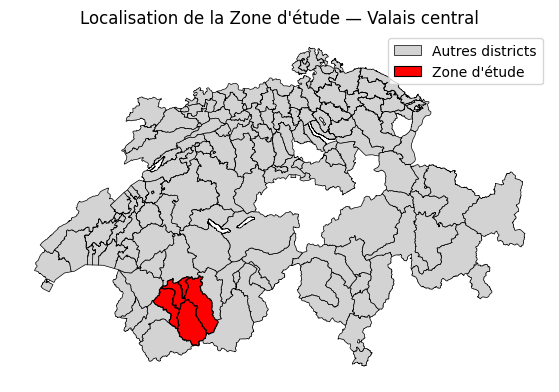

In [186]:
# Sélectionner les quatre districts
districts_etude = source_limite_districts[source_limite_districts["NAME"].isin([ "Sion","Hérens","Conthey","Sierre"])].copy()
# Vérifier la sélection
print("Districts sélectionnés :", districts_etude["NAME"].tolist())
print("Nombre de districts :", len(districts_etude))

# Créer une figure
fig, ax = plt.subplots(figsize=(6, 4))

# Tous les districts en gris
source_limite_districts.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="black",
    linewidth=0.5,
    label="Autres districts"
)

# Les quatre districts de la zone d'étude en jaune
districts_etude.plot(
    ax=ax,
    color="red",
    edgecolor="black",
    linewidth=0.8,
    label="Zone d'étude"
)

ax.set_title("Localisation de la Zone d'étude — Valais central")
ax.set_axis_off()
ax.legend()

plt.tight_layout()
plt.show()

### **3.2.2. Stress hydrique et Urbanisation**

In [187]:
#Visualisation du stress hydrique, des batiments et des routes sur le meme plot.

# Ouvrir le raster ET/ETp
with rasterio.open(RASTER_ET_ETP) as src:

    # Récupérer les géométries de chaque district
    geometries = [mapping(geom) for geom in districts_etude.geometry if geom is not None and not geom.is_empty]

    # Découper le raster
    et_etp_clip, transform = mask(
        src,
        geometries,
        crop=True,
        filled=False
    )

# Calculer l'emprise du raster découpé
height, width = et_etp_clip.shape[-2:]
bounds = array_bounds(height, width, transform)

extent_clip = (
    bounds[0], bounds[2],
    bounds[1], bounds[3]
)

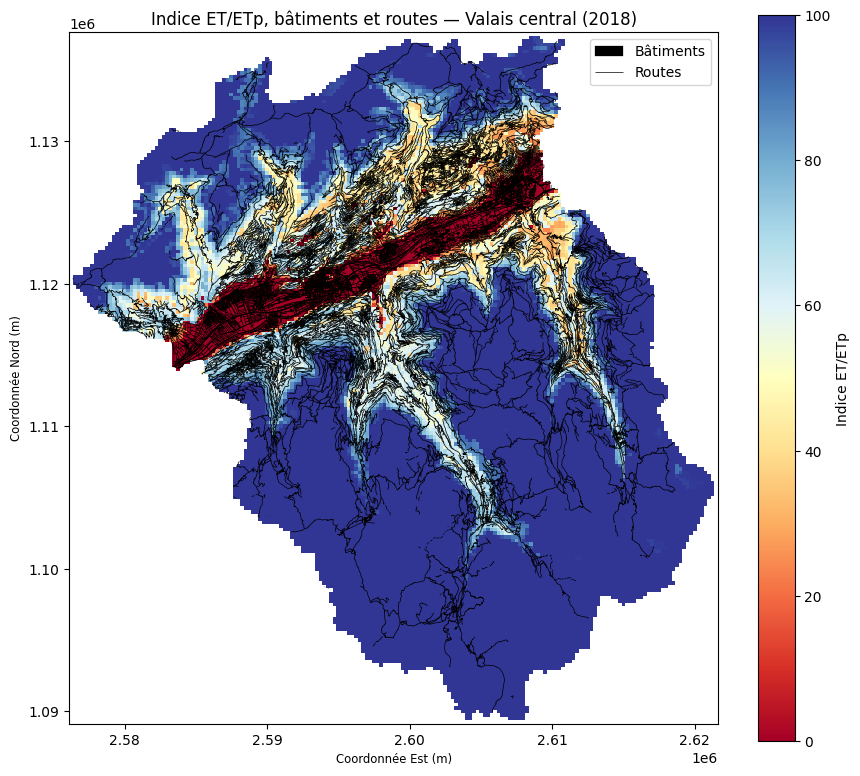

In [188]:
fig, ax = plt.subplots(figsize=(9, 8))

# Raster ET/ETp
im = ax.imshow(
    et_etp_clip[0],
    cmap="RdYlBu",
    extent=extent_clip,
    origin="upper"
)

# Bâtiments
source_batiments_clip.plot(
    ax=ax,
    facecolor="black",
    edgecolor="black",
    linewidth=0.2,
     label="Bâtiments"
)

# Routes
source_routes_clip.plot(
    ax=ax,
    color="black",
    linewidth=0.5,
     label="Routes"
)

# Colorbar
fig.colorbar(im, ax=ax, label="Indice ET/ETp")
ax.set_title("Indice ET/ETp, bâtiments et routes — Valais central (2018)")
ax.set_xlabel("Coordonnée Est (m)")
ax.set_ylabel("Coordonnée Nord (m)")

# Légende
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

On observe que les secteurs où les bâtiments et les routes sont particulièrement concentrés présentent généralement des valeurs plus faibles de l'indice ET/ETp. Cette relation est purement visuelle et motive la suite du projet, consacrée à l'analyse statistique de ces relations. Nous allons en effet calculer la densité urbaine et la distance à la zone urbaine la plus proche pour chaque pixel forestier (§4).

---
## 4. Chaîne de pré-traitements : des données sources au tableau d'analyse

---
## 5. Modélisation : ajustement, évaluation et choix du modèle

---
## 6. Analyse des résidus

---
## 7. Carte des prédictions et incertitude

---
## 8. Export des résultats

---
## 9. Conclusion